# Phase 9 — MC-Dropout Uncertainty Mechanism

**Project:** Physics-Informed GAT for Diabetic Foot Plantar Thermography
**Notebook:** `08_mc_dropout.ipynb`

## ⚠️ READ BEFORE INTERPRETING ANY NUMBER IN THIS NOTEBOOK ⚠️

**The model has NOT been trained yet.** Training is Phase 10. Every model used
below is `DualBranchGAT` with **freshly-initialized, random weights**.

This notebook builds and validates the **MC-Dropout mechanism (the plumbing)**
using that untrained model:

- Does the train/eval toggle correctly isolate dropout layers? (Section 2)
- Is the model actually stochastic when MC-Dropout is on, and deterministic
  when it's off? (Section 3)
- Does `mc_dropout_predict()` produce clean, NaN-free, correctly-shaped,
  correctly-signed uncertainty statistics? (Sections 4–6)

**Every numeric "uncertainty" value produced here is scientifically
meaningless as an actual uncertainty estimate.** Random weights produce
random-ish, unstructured outputs by definition — there is no learned signal
yet for the model to be certain or uncertain *about*. The only thing being
validated is that the mechanism is bug-free, so it can be trusted when it is
reused on the real trained model in a later phase.

This caveat is repeated above every results printout below so nothing here
is ever mistaken for a real finding later.

In [2]:
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Add project root to sys.path so `from src...` imports work regardless of
# where Jupyter's working directory happens to be.
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import build_dataloaders, load_normalization_stats
from src.model import DualBranchGAT

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Project root:", PROJECT_ROOT)
print("Processed dir:", PROCESSED_DIR)
print("Torch version:", torch.__version__)

Project root: c:\workstation\3RD YEAR\Diabetic_Foot
Processed dir: c:\workstation\3RD YEAR\Diabetic_Foot\data\processed
Torch version: 2.11.0+cu128


## Section 1 — Setup

Seed the notebook once (for reproducibility of the *sequence* of experiments
run below — **not** to make individual MC-Dropout passes identical to each
other, which would defeat the entire point of MC-Dropout). Load the
train-derived normalization stats (Phase 7), build the real dataloaders
(Phase 8's `build_dataloaders`), and instantiate a fresh, untrained
`DualBranchGAT`.

Printing the full module list lets us visually confirm, before touching any
logic, exactly which submodules are `Dropout`/`Dropout2d` (must become
stochastic under MC-Dropout) versus everything else, especially
`GroupNorm` (must stay deterministic — see Section 2 markdown).

In [3]:
print("=== SECTION 1: Setup ===")

torch.manual_seed(42)

normalization_stats = load_normalization_stats(PROCESSED_DIR)
print("Loaded normalization_stats.json, keys:", list(normalization_stats.keys()))

loaders = build_dataloaders(PROCESSED_DIR, normalization_stats, batch_size=16)
train_loader = loaders["train"]
val_loader = loaders["val"]
test_loader = loaders["test"]

print(f"train_dataset: {len(loaders['train_dataset'])} samples")
print(f"val_dataset:   {len(loaders['val_dataset'])} samples")
print(f"test_dataset:  {len(loaders['test_dataset'])} samples")

model = DualBranchGAT(use_graph_branch=True, use_image_branch=True)
model.eval()  # baseline state before any MC-Dropout toggling

print("\n=== SECTION 1: Model Module List ===")
for name, module in model.named_modules():
    if name == "":
        continue
    print(f"{name:35s} {type(module).__name__}")

=== SECTION 1: Setup ===
Loaded normalization_stats.json, keys: ['node_feature_names', 'node_feature_mean', 'node_feature_std', 'raw_tissue_mean', 'raw_tissue_std', 'relative_tissue_mean', 'relative_tissue_std', 'computed_from_split', 'train_subject_foot_count']
train_dataset: 232 samples
val_dataset:   50 samples
test_dataset:  52 samples

=== SECTION 1: Model Module List ===
graph_branch                        GraphBranch
graph_branch.gat1                   EdgeGATLayer
graph_branch.gat1.W_node            Linear
graph_branch.gat1.W_edge            Linear
graph_branch.gat1.leaky_relu        LeakyReLU
graph_branch.gat1.dropout           Dropout
graph_branch.norm                   GroupNorm
graph_branch.dropout                Dropout
graph_branch.gat2                   EdgeGATLayer
graph_branch.gat2.W_node            Linear
graph_branch.gat2.W_edge            Linear
graph_branch.gat2.leaky_relu        LeakyReLU
graph_branch.gat2.dropout           Dropout
image_branch                    

## Section 2 — The MC-Dropout Toggle: `enable_mc_dropout(model)`

MC-Dropout needs a model where:
- **Dropout / Dropout2d layers are stochastic** (`.train()` behavior — they
  randomly zero activations on every forward pass).
- **Every other layer behaves exactly like normal inference** (`.eval()`
  behavior).

The tricky part is that `model.train()` / `model.eval()` are all-or-nothing
switches — calling `model.train()` would also put every other layer (like
`GroupNorm`) into "training mode." `GroupNorm` computes its statistics from
each individual sample's own channels, not from a running batch average
(unlike `BatchNorm`), so its math is identical in train or eval mode — but
we still start from `.eval()` as the correct, explicit baseline rather than
relying on that being true by luck.

`enable_mc_dropout()` therefore does this in two steps: call `model.eval()`
first, then walk every submodule and call `.train()` specifically on the
ones that are `nn.Dropout` or `nn.Dropout2d`, leaving everything else in
`eval()` mode.

In [4]:
def enable_mc_dropout(model: nn.Module) -> nn.Module:
    """Puts `model` in eval mode, then re-enables train-mode (stochastic)
    behavior specifically on Dropout / Dropout2d layers, leaving every other
    layer (GroupNorm, Linear, Conv2d, ...) in eval mode.
    """
    model.eval()
    for module in model.modules():
        if isinstance(module, (nn.Dropout, nn.Dropout2d)):
            module.train()
    return model


print("=== SECTION 2: MC-Dropout Toggle Check ===")
print("[Untrained model — this section validates PLUMBING, not uncertainty values.]")

enable_mc_dropout(model)

all_pass = True
for name, module in model.named_modules():
    if name == "":
        continue
    is_dropout = isinstance(module, (nn.Dropout, nn.Dropout2d))
    expected = True if is_dropout else False
    ok = (module.training == expected)
    status = "OK" if ok else "MISMATCH"
    if not ok:
        all_pass = False
    print(f"{name:35s} {type(module).__name__:15s} training={module.training!s:5s} [{status}]")

print()
if all_pass:
    print("PASS: every Dropout/Dropout2d module has .training == True, "
          "and every other module has .training == False.")
else:
    print("FAIL: at least one module is in the wrong mode — see MISMATCH rows above.")

toggle_check_passed = all_pass

=== SECTION 2: MC-Dropout Toggle Check ===
[Untrained model — this section validates PLUMBING, not uncertainty values.]
graph_branch                        GraphBranch     training=False [OK]
graph_branch.gat1                   EdgeGATLayer    training=False [OK]
graph_branch.gat1.W_node            Linear          training=False [OK]
graph_branch.gat1.W_edge            Linear          training=False [OK]
graph_branch.gat1.leaky_relu        LeakyReLU       training=False [OK]
graph_branch.gat1.dropout           Dropout         training=True  [OK]
graph_branch.norm                   GroupNorm       training=False [OK]
graph_branch.dropout                Dropout         training=True  [OK]
graph_branch.gat2                   EdgeGATLayer    training=False [OK]
graph_branch.gat2.W_node            Linear          training=False [OK]
graph_branch.gat2.W_edge            Linear          training=False [OK]
graph_branch.gat2.leaky_relu        LeakyReLU       training=False [OK]
graph_branch.gat

## Section 3 — Stochasticity Contrast Test

Section 2 confirmed *which* modules are in which mode. This section confirms
that toggling actually **changes model behavior** in the expected direction:

- **(a)** With `enable_mc_dropout(model)` active, running the *same* batch
  through the model twice should give **different** outputs (dropout is
  genuinely randomly zeroing activations each pass).
- **(b)** With plain `model.eval()` (MC-Dropout off), running the same batch
  through twice should give **identical** outputs (everything is
  deterministic).

(b) is the contrast case: it proves that whatever stochasticity we saw in
(a) came specifically from the dropout toggle, and not from some other
unrelated source of randomness in the model.

In [5]:
print("=== SECTION 3: Stochasticity Contrast Test ===")
print("[Untrained model — this section validates PLUMBING, not uncertainty values.]")

# Pull one real batch from the training set.
batch = next(iter(train_loader))

# --- (a) MC-Dropout ON: two passes on the same batch should DIFFER ---
enable_mc_dropout(model)
with torch.no_grad():
    out_a1 = model(batch)
    out_a2 = model(batch)
max_diff_mc = (out_a1 - out_a2).abs().max().item()
mc_stochastic_pass = max_diff_mc > 0.0

print(f"(a) MC-Dropout ON  — max abs difference between two passes: {max_diff_mc:.6f}")
print("    PASS" if mc_stochastic_pass else "    FAIL",
      "- outputs differ between passes (dropout is genuinely active)" if mc_stochastic_pass
      else "- outputs did NOT differ; dropout does not appear active")

# --- (b) Plain eval(): two passes on the same batch should be IDENTICAL ---
model.eval()
with torch.no_grad():
    out_b1 = model(batch)
    out_b2 = model(batch)
max_diff_eval = (out_b1 - out_b2).abs().max().item()
eval_deterministic_pass = (max_diff_eval == 0.0)

print(f"(b) Plain eval()   — max abs difference between two passes: {max_diff_eval:.10f}")
print("    PASS" if eval_deterministic_pass else "    FAIL",
      "- outputs identical (model is deterministic with dropout off)" if eval_deterministic_pass
      else "- outputs differ; something is non-deterministic even with dropout off")

print()
section3_passed = mc_stochastic_pass and eval_deterministic_pass
print("SECTION 3 OVERALL:", "PASS" if section3_passed else "FAIL")

=== SECTION 3: Stochasticity Contrast Test ===
[Untrained model — this section validates PLUMBING, not uncertainty values.]
(a) MC-Dropout ON  — max abs difference between two passes: 0.218232
    PASS - outputs differ between passes (dropout is genuinely active)
(b) Plain eval()   — max abs difference between two passes: 0.0000000000
    PASS - outputs identical (model is deterministic with dropout off)

SECTION 3 OVERALL: PASS


## Section 4 — Uncertainty Decomposition: `mc_dropout_predict()`

Runs `T` independent stochastic forward passes and decomposes the total
predictive uncertainty into two standard components (the BALD-style /
mutual-information decomposition):

- **Predictive entropy** — entropy of the *averaged* probability across all
  T passes. This is the **total** uncertainty.
- **Expected entropy** — the average, across all T passes, of *each
  individual pass's* entropy. This is the **aleatoric** (data-inherent)
  uncertainty component.
- **Epistemic uncertainty** = predictive entropy − expected entropy. This is
  the **model** uncertainty component — how much the T passes disagree with
  each other, above and beyond each pass's own built-in uncertainty.

A small clamp (`1e-6` to `1 - 1e-6`) is applied to every probability before
any `log()` call, since `log(0)` is `-inf` and would poison every downstream
statistic with `NaN`.

In [6]:
def binary_entropy(p: torch.Tensor, eps: float = 1e-6) -> torch.Tensor:
    """Binary entropy -[p*log(p) + (1-p)*log(1-p)], with p clamped away from
    exactly 0 or 1 to avoid NaN from log(0).
    """
    p = torch.clamp(p, eps, 1.0 - eps)
    return -(p * torch.log(p) + (1.0 - p) * torch.log(1.0 - p))


def mc_dropout_predict(model: nn.Module, batch: dict, T: int = 30,
                        graph_topology: str = "base",
                        image_key: str = "colormap_image") -> dict:
    """Runs T stochastic MC-Dropout forward passes on `batch` and returns a
    dict of per-sample uncertainty statistics: mean_prob, std_prob,
    predictive_entropy (total), expected_entropy (aleatoric proxy), and
    epistemic_uncertainty (predictive_entropy - expected_entropy).
    """
    enable_mc_dropout(model)

    per_pass_probs = []
    with torch.no_grad():
        for _ in range(T):
            logits = model(batch, graph_topology=graph_topology, image_key=image_key)
            per_pass_probs.append(torch.sigmoid(logits))

    probs = torch.stack(per_pass_probs, dim=0)  # (T, B)

    mean_prob = probs.mean(dim=0)               # (B,)
    std_prob = probs.std(dim=0)                 # (B,)

    predictive_entropy = binary_entropy(mean_prob)          # (B,) total uncertainty
    per_pass_entropy = binary_entropy(probs)                # (T, B)
    expected_entropy = per_pass_entropy.mean(dim=0)         # (B,) aleatoric proxy
    epistemic_uncertainty = predictive_entropy - expected_entropy  # (B,)

    return {
        "mean_prob": mean_prob,
        "std_prob": std_prob,
        "predictive_entropy": predictive_entropy,
        "expected_entropy": expected_entropy,
        "epistemic_uncertainty": epistemic_uncertainty,
    }


print("=== SECTION 4: mc_dropout_predict() defined ===")
print("Signature: mc_dropout_predict(model, batch, T=30, graph_topology='base', "
      "image_key='colormap_image')")

=== SECTION 4: mc_dropout_predict() defined ===
Signature: mc_dropout_predict(model, batch, T=30, graph_topology='base', image_key='colormap_image')


## Section 5 — Mechanism Test (Untrained Model)

**⚠️ Untrained model — every number below is a plumbing check, not a real
uncertainty result. ⚠️**

Runs `mc_dropout_predict()` once with `T=30` on one real batch and checks:

- All 5 returned tensors have the correct shape `(B,)` and contain zero
  `NaN`s.
- `std_prob` is **not uniformly zero** — proving the T passes are genuinely
  spreading out, not silently collapsing to one deterministic value.
- `epistemic_uncertainty` stays **non-negative** (small floating-point
  slack aside) — a required sanity property of the
  total = aleatoric + epistemic decomposition.

In [7]:
print("=== SECTION 5: Mechanism Test (UNTRAINED MODEL — not a real result) ===")

results = mc_dropout_predict(model, batch, T=30)

nan_free = True
print("--- Shapes & NaN check ---")
for key, tensor in results.items():
    has_nan = torch.isnan(tensor).any().item()
    if has_nan:
        nan_free = False
    print(f"{key:25s} shape={tuple(tensor.shape)!s:10s} NaNs={has_nan}")

std_prob = results["std_prob"]
print("\n--- std_prob (is the model genuinely producing spread across T passes?) ---")
print(f"min={std_prob.min().item():.6f}  mean={std_prob.mean().item():.6f}  max={std_prob.max().item():.6f}")
std_not_uniform_zero = std_prob.max().item() > 1e-8
print("PASS" if std_not_uniform_zero else "FAIL",
      "- std_prob is not uniformly zero" if std_not_uniform_zero
      else "- std_prob is (near) zero everywhere; T passes are collapsing to one value")

epi = results["epistemic_uncertainty"]
print("\n--- epistemic_uncertainty (must stay non-negative) ---")
print(f"min={epi.min().item():.6f}  mean={epi.mean().item():.6f}  max={epi.max().item():.6f}")
TOLERANCE = -1e-4
epi_non_negative = bool((epi >= TOLERANCE).all().item())
if epi_non_negative:
    print(f"PASS - all epistemic_uncertainty values >= {TOLERANCE} (non-negative within tolerance)")
else:
    n_bad = int((epi < TOLERANCE).sum().item())
    print(f"FAIL - {n_bad} value(s) fell below {TOLERANCE} -- flagging loudly, this should not happen")

section5_passed = nan_free and std_not_uniform_zero and epi_non_negative
print("\nSECTION 5 OVERALL:", "PASS" if section5_passed else "FAIL")

=== SECTION 5: Mechanism Test (UNTRAINED MODEL — not a real result) ===
--- Shapes & NaN check ---
mean_prob                 shape=(16,)      NaNs=False
std_prob                  shape=(16,)      NaNs=False
predictive_entropy        shape=(16,)      NaNs=False
expected_entropy          shape=(16,)      NaNs=False
epistemic_uncertainty     shape=(16,)      NaNs=False

--- std_prob (is the model genuinely producing spread across T passes?) ---
min=0.022212  mean=0.028648  max=0.038582
PASS - std_prob is not uniformly zero

--- epistemic_uncertainty (must stay non-negative) ---
min=0.000955  mean=0.001628  max=0.002895
PASS - all epistemic_uncertainty values >= -0.0001 (non-negative within tolerance)

SECTION 5 OVERALL: PASS


## Section 6 — T-Selection Convergence Check

**⚠️ Untrained model — this is a mechanism-stability check, not a
meaningful uncertainty result about the diabetic foot classification task.
⚠️**

Runs `mc_dropout_predict()` on the *same single batch* with
`T ∈ {5, 10, 20, 30, 50, 100}` and tracks the batch-mean `std_prob` at each
`T`. As `T` grows, this value should stabilize (diminishing returns) rather
than keep drifting — that stabilization point is what tells us `T=30` is a
reasonable default to reuse once this mechanism is applied to the real
trained model in a later phase.

=== SECTION 6: T-Selection Convergence Check (UNTRAINED MODEL) ===
    T   batch-mean std_prob
    5              0.028122
   10              0.033081
   20              0.029809
   30              0.028746
   50              0.029243
  100              0.029517


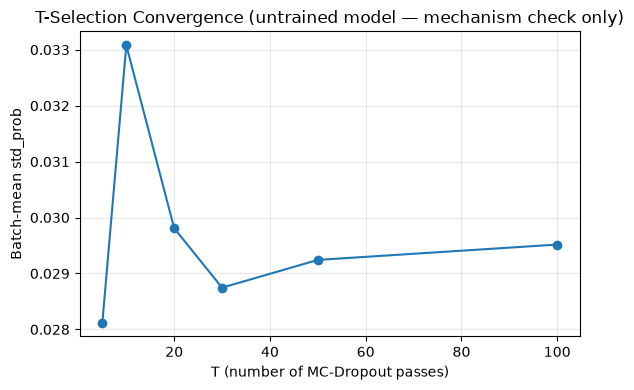


Note: this curve shows whether the ESTIMATE stabilizes as T grows, not whether the diabetic-foot task is well-modeled -- the model is untrained.


In [8]:
print("=== SECTION 6: T-Selection Convergence Check (UNTRAINED MODEL) ===")

T_values = [5, 10, 20, 30, 50, 100]
batch_mean_std_prob = []

for T in T_values:
    r = mc_dropout_predict(model, batch, T=T)
    batch_mean_std_prob.append(r["std_prob"].mean().item())

print(f"{'T':>5s}  {'batch-mean std_prob':>20s}")
for T, val in zip(T_values, batch_mean_std_prob):
    print(f"{T:5d}  {val:20.6f}")

plt.figure(figsize=(6, 4))
plt.plot(T_values, batch_mean_std_prob, marker="o")
plt.xlabel("T (number of MC-Dropout passes)")
plt.ylabel("Batch-mean std_prob")
plt.title("T-Selection Convergence (untrained model — mechanism check only)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nNote: this curve shows whether the ESTIMATE stabilizes as T grows, "
      "not whether the diabetic-foot task is well-modeled -- the model is untrained.")

## Section 7 — Save the Validated Mechanism to `src/mc_dropout.py`

Now that `enable_mc_dropout()` and `mc_dropout_predict()` (plus the
`binary_entropy` helper) have been validated above, they're written out to
`src/mc_dropout.py` using `inspect.getsource()` on the live function objects
defined in this notebook — the same pattern `src/model.py` used in Phase 8 —
so this file and the notebook can never drift out of sync. Phase 10
(training) and whichever later phase runs the real trained-model evaluation
can then `from src.mc_dropout import enable_mc_dropout, mc_dropout_predict`
without redefining anything.

In [9]:
import inspect

MC_DROPOUT_MODULE_PATH = PROJECT_ROOT / "src" / "mc_dropout.py"

module_docstring = '''"""
src/mc_dropout.py -- MC-Dropout uncertainty mechanism (Phase 9).

Diabetic foot thermography project. Written out programmatically by
08_mc_dropout.ipynb Section 7 (via inspect.getsource on the live functions
defined in that notebook's Sections 2 and 4), so this file and the notebook
stay in sync.

IMPORTANT: every function here was validated in 08_mc_dropout.ipynb against a
freshly-initialized, UNTRAINED DualBranchGAT. That notebook confirmed:
  - enable_mc_dropout() correctly isolates Dropout/Dropout2d in train mode
    while leaving every other layer (GroupNorm, Linear, Conv2d, ...) in eval
    mode (Section 2).
  - The toggle produces genuinely stochastic outputs when active, and
    genuinely deterministic outputs when inactive (Section 3).
  - mc_dropout_predict() produces NaN-free, correctly-shaped, non-negative-
    epistemic-uncertainty statistics (Section 5), and a stable estimate by
    around T=30 (Section 6).

None of that validation used real (trained) predictive signal -- it only
proves the plumbing is correct. Actual uncertainty numbers only become
meaningful once these functions are reused on a trained model.
"""

import torch
import torch.nn as nn


'''

source = module_docstring
source += inspect.getsource(enable_mc_dropout) + "\n\n"
source += inspect.getsource(binary_entropy) + "\n\n"
source += inspect.getsource(mc_dropout_predict) + "\n"

MC_DROPOUT_MODULE_PATH.parent.mkdir(parents=True, exist_ok=True)
MC_DROPOUT_MODULE_PATH.write_text(source)

print("=== SECTION 7: Saved src/mc_dropout.py ===")
print(f"Written to: {MC_DROPOUT_MODULE_PATH}")
print(f"File size: {MC_DROPOUT_MODULE_PATH.stat().st_size} bytes")

# Re-import check: fresh import from the saved file should work and match behavior.
import importlib
import src.mc_dropout as mc_dropout_module
importlib.reload(mc_dropout_module)
reload_check = hasattr(mc_dropout_module, "enable_mc_dropout") and hasattr(mc_dropout_module, "mc_dropout_predict")
print("PASS" if reload_check else "FAIL", "- src/mc_dropout.py imports cleanly and exposes both functions")

section7_passed = reload_check

=== SECTION 7: Saved src/mc_dropout.py ===
Written to: c:\workstation\3RD YEAR\Diabetic_Foot\src\mc_dropout.py
File size: 3452 bytes
PASS - src/mc_dropout.py imports cleanly and exposes both functions


## Section 8 — Final Summary

In [10]:
print("=== SECTION 8: FINAL SUMMARY ===")
print()
print("REMINDER: every uncertainty number produced in this notebook came from an")
print("UNTRAINED, randomly-initialized DualBranchGAT. None of it is a real scientific")
print("finding about the diabetic foot classification task -- it only validates that")
print("the MC-Dropout MECHANISM is bug-free and ready to be reused on the trained")
print("model in a later phase.")
print()

issues = []

print(f"Section 2 (train/eval toggle test):        {'PASS' if toggle_check_passed else 'FAIL'}")
if not toggle_check_passed:
    issues.append("Section 2: toggle check failed (see mismatch rows above).")

print(f"Section 3 (stochasticity contrast test):    {'PASS' if section3_passed else 'FAIL'}")
if not section3_passed:
    issues.append("Section 3: stochasticity contrast test failed.")

print(f"Section 5 (mechanism test, 0 NaNs, "
      f"non-uniform std_prob, non-negative epistemic): {'PASS' if section5_passed else 'FAIL'}")
if not section5_passed:
    issues.append("Section 5: mechanism test failed (see details above).")

print(f"Section 6 (T-selection convergence):        produced -- see plot and table above")
print(f"  T=30 batch-mean std_prob: {batch_mean_std_prob[T_values.index(30)]:.6f} "
      f"(vs T=100: {batch_mean_std_prob[T_values.index(100)]:.6f})")

print(f"Section 7 (src/mc_dropout.py saved):        {'PASS' if section7_passed else 'FAIL'}")
if not section7_passed:
    issues.append("Section 7: src/mc_dropout.py failed to save/import cleanly.")

print()
if not issues:
    print("0 mechanism issues found.")
else:
    print(f"{len(issues)} issue(s) found:")
    for i in issues:
        print(" -", i)

print()
print("Ready to proceed to Phase 10: training (with mc_dropout_predict() reused")
print("on the real trained model to produce the first MEANINGFUL uncertainty")
print("estimates).")

=== SECTION 8: FINAL SUMMARY ===

REMINDER: every uncertainty number produced in this notebook came from an
UNTRAINED, randomly-initialized DualBranchGAT. None of it is a real scientific
finding about the diabetic foot classification task -- it only validates that
the MC-Dropout MECHANISM is bug-free and ready to be reused on the trained
model in a later phase.

Section 2 (train/eval toggle test):        PASS
Section 3 (stochasticity contrast test):    PASS
Section 5 (mechanism test, 0 NaNs, non-uniform std_prob, non-negative epistemic): PASS
Section 6 (T-selection convergence):        produced -- see plot and table above
  T=30 batch-mean std_prob: 0.028746 (vs T=100: 0.029517)
Section 7 (src/mc_dropout.py saved):        PASS

0 mechanism issues found.

Ready to proceed to Phase 10: training (with mc_dropout_predict() reused
on the real trained model to produce the first MEANINGFUL uncertainty
estimates).
